# AIDL01 - Fundamentals of Machine Learning Project
## Part 1: Regression - Invoice Payment Delay Prediction

* **Student Name**: Fotis Papadopoulos
* **Student ID**: 0114
* **Course**: MSc in Artificial Intelligence & Deep Learning
* **Instructor**: Dr. Grigorios Nikolaou
* **Academic Year**: 2025 - 2026
* **Date**: June 2026

In [1]:
import os
import urllib.request
import pandas as pd

# dataset source: IBM Watson Analytics
url = "https://raw.githubusercontent.com/pthiagu2/DataMining/master/WA_Fn-UseC_-Accounts-Receivable.csv"
local_filename = "WA_Fn-UseC_-Accounts-Receivable.csv"

# download the file if it doesn't exist locally
if not os.path.exists(local_filename):
    print("Downloading dataset from IBM/GitHub source...")
    urllib.request.urlretrieve(url, local_filename)
    print("Download complete.")
else:
    print("Dataset loaded from local storage.")

# Load the dataset
df = pd.read_csv(local_filename)

# Display structural information
df.info()

Download complete.
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2466 entries, 0 to 2465
Data columns (total 12 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   countryCode    2466 non-null   int64  
 1   customerID     2466 non-null   object 
 2   PaperlessDate  2466 non-null   object 
 3   invoiceNumber  2466 non-null   int64  
 4   InvoiceDate    2466 non-null   object 
 5   DueDate        2466 non-null   object 
 6   InvoiceAmount  2466 non-null   float64
 7   Disputed       2466 non-null   object 
 8   SettledDate    2466 non-null   object 
 9   PaperlessBill  2466 non-null   object 
 10  DaysToSettle   2466 non-null   int64  
 11  DaysLate       2466 non-null   int64  
dtypes: float64(1), int64(4), object(7)
memory usage: 231.3+ KB


## 1. Problem Definition
* **Objective**: Predict the number of days to settle/pay an invoice (`DaysToSettle`) using supervised regression.
* **ML Benefit**: Custom, dynamic predictions per invoice to replace static averages (DSO), enabling proactive accounts receivable management.
* **Leakage Control**: Exclude future-looking variables (`SettledDate`,
`DaysLate`) that are unknown at the time of invoicing.

## 2. Exploratory Data Analysis (EDA)
In this section, we analyze the structure of our dataset, identify numerical and categorical variables, review basic statistics, and visualize key distributions.

### 2.1. Initial Data Inspection

We inspect the dataset to understand its size and to separate the features into numerical and categorical columns.

In [2]:
# Print the shape (rows and columns) of the dataset
print(f"Dataset Dimensions: {df.shape[0]} rows and {df.shape[1]} columns.\n")

# print list of numerical variables
num_cols = df.select_dtypes(include=['number']).columns.tolist()
print(f"Numerical Variables ({len(num_cols)}):")
print(num_cols)

# print list of categorical variables
cat_cols = df.select_dtypes(include=['object']).columns.tolist()
print(f"\nCategorical Variables ({len(cat_cols)}):")
print(cat_cols)

print(f"\nThere are {len(num_cols)} numerical variables and {len(cat_cols)} categorical variables.")

Dataset Dimensions: 2466 rows and 12 columns.

Numerical Variables (5):
['countryCode', 'invoiceNumber', 'InvoiceAmount', 'DaysToSettle', 'DaysLate']

Categorical Variables (7):
['customerID', 'PaperlessDate', 'InvoiceDate', 'DueDate', 'Disputed', 'SettledDate', 'PaperlessBill']

There are 5 numerical variables and 7 categorical variables.


In [3]:
# statistical summary table of numerical variables
print("Descriptive Statistics for Numerical Features:")
display(df.describe())

# distribution counts for categorical billing types and disputes
print("\nInvoice Count by Billing Type (PaperlessBill):")
print(df['PaperlessBill'].value_counts())

print("\nInvoice Count by Dispute Status (Disputed):")
print(df['Disputed'].value_counts())

Descriptive Statistics for Numerical Features:


,countryCode,invoiceNumber,InvoiceAmount,DaysToSettle,DaysLate
count,2466.000000,2.466000e+03,2466.000000,2466.00000,2466.000000
mean,620.446067,4.978431e+09,59.895856,26.44485,3.442417
std,215.933610,2.884272e+09,20.435838,12.33493,6.290607
min,391.000000,6.113650e+05,5.260000,0.00000,0.000000
25%,406.000000,2.528854e+09,46.400000,18.00000,0.000000
50%,770.000000,4.964228e+09,60.560000,26.00000,0.000000
75%,818.000000,7.494512e+09,73.765000,35.00000,5.000000
max,897.000000,9.990244e+09,128.280000,75.00000,45.000000



Invoice Count by Billing Type (PaperlessBill):
PaperlessBill
Paper         1263
Electronic    1203
Name: count, dtype: int64

Invoice Count by Dispute Status (Disputed):
Disputed
No     1905
Yes     561
Name: count, dtype: int64


### 2.3. Visualizing Key Numerical Distributions

We plot the distributions of invoice payment times and invoice amounts to check their shape and spread.

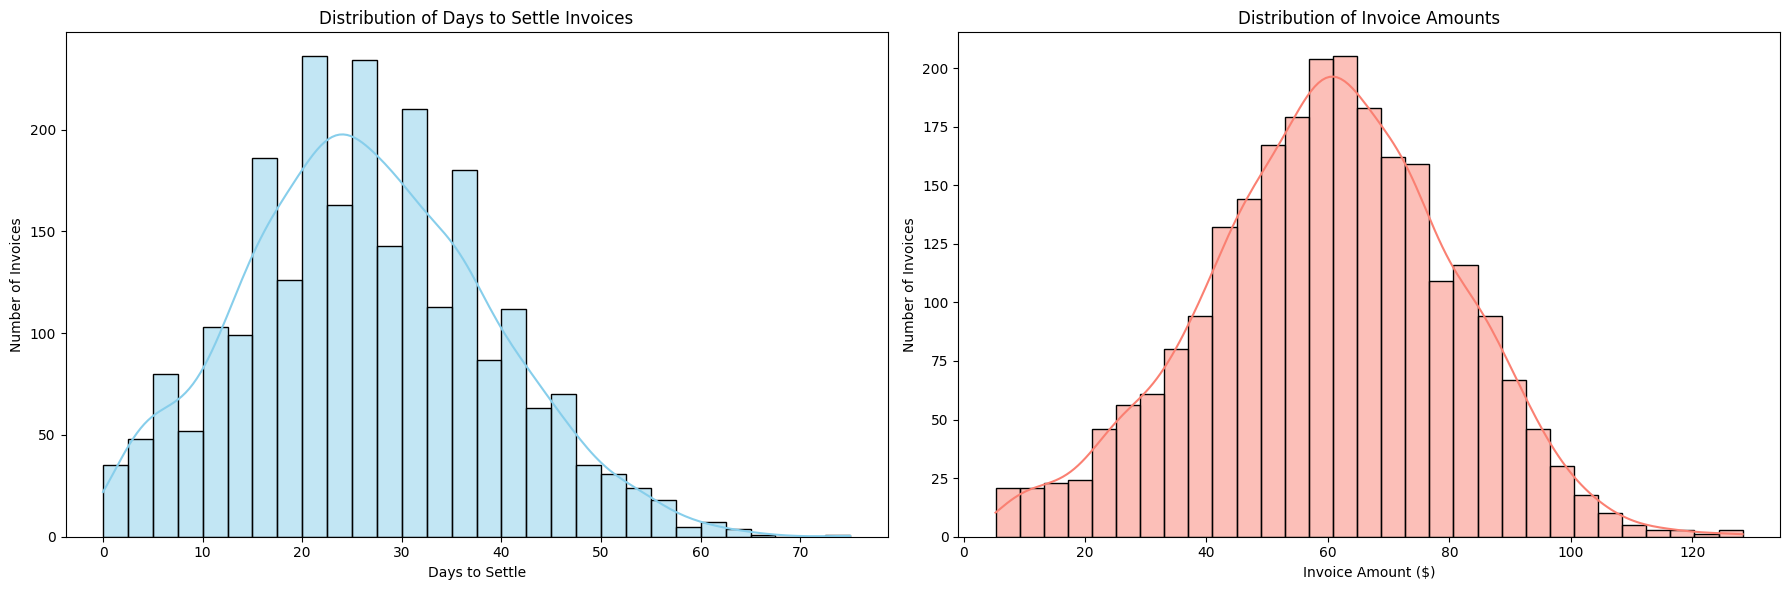

In [4]:
import matplotlib.pyplot as plt
import seaborn as sns

# figure with 2 subplots
fig, axes = plt.subplots(1, 2, figsize=(18, 6))

# we want to see how many days it usually takes for invoices to get paid.
# we use a histogram to see the shape of the data.
sns.histplot(x='DaysToSettle', data=df, kde=True, ax=axes[0], color='skyblue')
axes[0].set_title('Distribution of Days to Settle Invoices')
axes[0].set_xlabel('Days to Settle')
axes[0].set_ylabel('Number of Invoices')

# we do this to see the range of the invoices we send to our customers.
# Most invoices are small, but we want to see if there are very large ones.
sns.histplot(x='InvoiceAmount', data=df, kde=True, ax=axes[1], color='salmon')
axes[1].set_title('Distribution of Invoice Amounts')
axes[1].set_xlabel('Invoice Amount ($)')
axes[1].set_ylabel('Number of Invoices')

# Show the plots
plt.tight_layout()
plt.show()

### 2.4. Bivariate Analysis: Features vs. Payment Time

We use a boxplot and a scatterplot to see how dispute status and invoice amounts affect the payment time.

/tmp/ipykernel_4517/3790107629.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='Disputed', y='DaysToSettle', data=df, ax=axes[0], palette='pastel')


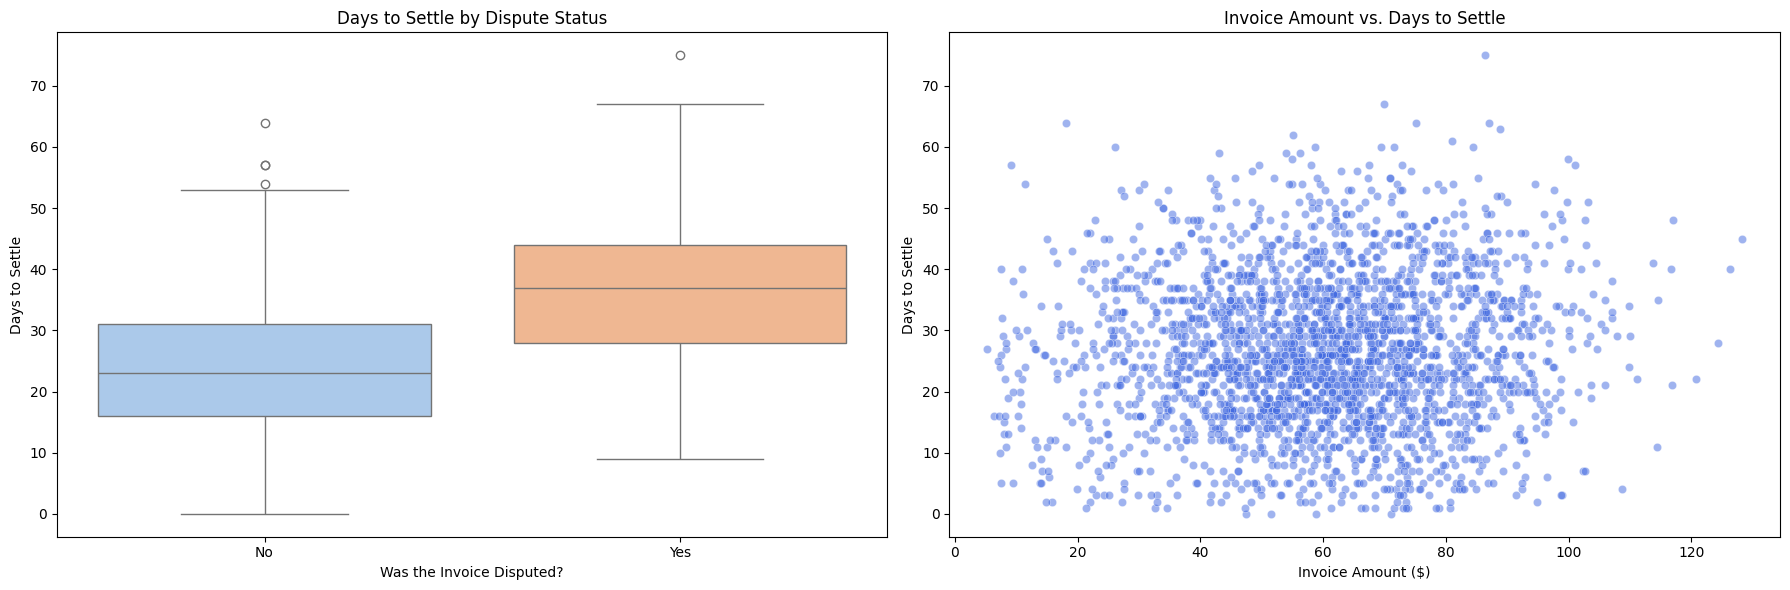

In [5]:
# We create 2 subplots side-by-side to see how features affect payment time
fig, axes = plt.subplots(1, 2, figsize=(18, 6))

# boxplot: DaysToSettle and Disputed
# we want to see if customers take longer to pay when they dispute the invoice.
sns.boxplot(x='Disputed', y='DaysToSettle', data=df, ax=axes[0], palette='pastel')
axes[0].set_title('Days to Settle by Dispute Status')
axes[0].set_xlabel('Was the Invoice Disputed?')
axes[0].set_ylabel('Days to Settle')

# scatterplot: InvoiceAmount and DaysToSettle
# we want to see if larger invoice amounts lead to longer payment delays.
sns.scatterplot(x='InvoiceAmount', y='DaysToSettle', data=df, ax=axes[1], alpha=0.5, color='royalblue')
axes[1].set_title('Invoice Amount vs. Days to Settle')
axes[1].set_xlabel('Invoice Amount ($)')
axes[1].set_ylabel('Days to Settle')

plt.tight_layout()
plt.show()

## 3. Data Preprocessing
Here we clean our data, create new features, convert text categories into numbers (one-hot encoding), split the dataset into train and test sets, and scale the features.

### 3.1 Feature Engineering (Payment Terms)
We calculate the allowed payment terms in days by subtracting the due date from the invoice date. Additionally, we extract three new time-based features from the invoice date:
1. Day of the week (`InvoiceDayOfWeek`)
2. Day of the month (`InvoiceDay`)
3. Month of the year (`InvoiceMonth`)

In [6]:
# Convert date columns to datetime format
df['InvoiceDate'] = pd.to_datetime(df['InvoiceDate'])
df['DueDate'] = pd.to_datetime(df['DueDate'])

# Feature Engineering: Extract month, day, and day of week from InvoiceDate
df['InvoiceMonth'] = df['InvoiceDate'].dt.month
df['InvoiceDay'] = df['InvoiceDate'].dt.day
df['InvoiceDayOfWeek'] = df['InvoiceDate'].dt.dayofweek

# Print sample results to check
print(df[['InvoiceDate', 'InvoiceMonth', 'InvoiceDay', 'InvoiceDayOfWeek']].head())

df['PaymentTerms'] = (df['DueDate'] - df['InvoiceDate']).dt.days

# 3. Print the counts of each unique payment term in the dataset
print("\nFrequency of each Payment Term:")
print(df['PaymentTerms'].value_counts())

  InvoiceDate  InvoiceMonth  InvoiceDay  InvoiceDayOfWeek
0  2013-01-02             1           2                 2
1  2013-01-26             1          26                 5
2  2013-07-03             7           3                 2
3  2013-02-10             2          10                 6
4  2012-10-25            10          25                 3

Frequency of each Payment Term:
PaymentTerms
30    2466
Name: count, dtype: int64


### 3.2 Selecting Features and Target
We define our features ($X$) and target ($y$). We drop IDs and future-looking variables to prevent data leakage.

In [7]:
# select only variables that we know at the time of invoicing
# we drop customerID, settledDate, DaysLate, and invoiceNumber
# We also drop PaymentTerms because it is constant (30 days for all rows) and has no predictive power
# Select only variables known at the time of invoicing (excluding countryCode)
X = df[['InvoiceAmount', 'Disputed', 'PaperlessBill', 'InvoiceMonth', 'InvoiceDay', 'InvoiceDayOfWeek']].copy()
y = df['DaysToSettle']

/tmp/ipykernel_4517/3970343085.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='Disputed', data=df, ax=axes[0, 0], palette='pastel')
/tmp/ipykernel_4517/3970343085.py:14: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='PaperlessBill', data=df, ax=axes[0, 1], palette='pastel')
/tmp/ipykernel_4517/3970343085.py:22: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='InvoiceDayOfWeek', data=df, ax=axes[0, 2], palette='pastel', order=list(range(7)))
/tmp/ipykernel_4517/3970343085.py:26: UserWarning: set_ticklabels() should only be used

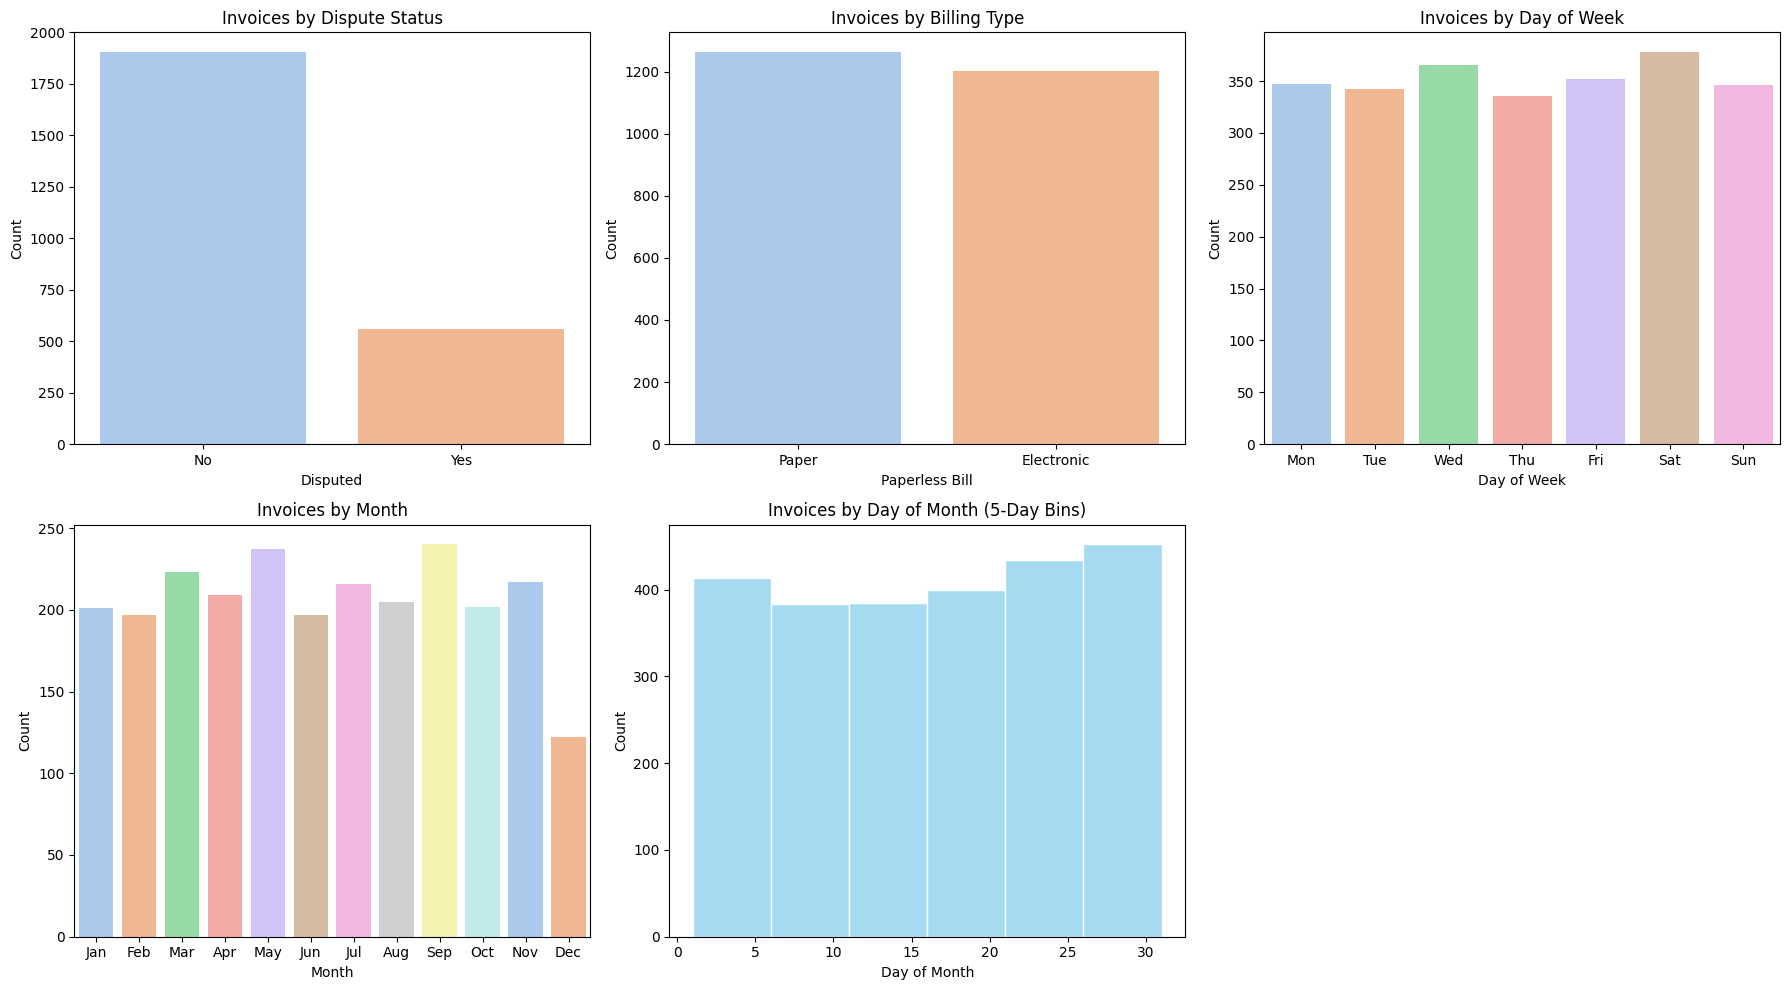

In [8]:
import matplotlib.pyplot as plt
import seaborn as sns

# We create a 2x3 grid of subplots (6 slots total, we will use 5)
fig, axes = plt.subplots(2, 3, figsize=(18, 10))

# 1. Row 0, Col 0: Disputed
sns.countplot(x='Disputed', data=df, ax=axes[0, 0], palette='pastel')
axes[0, 0].set_title('Invoices by Dispute Status')
axes[0, 0].set_xlabel('Disputed')
axes[0, 0].set_ylabel('Count')

# 2. Row 0, Col 1: PaperlessBill
sns.countplot(x='PaperlessBill', data=df, ax=axes[0, 1], palette='pastel')
axes[0, 1].set_title('Invoices by Billing Type')
axes[0, 1].set_xlabel('Paperless Bill')
axes[0, 1].set_ylabel('Count')

# 3. Row 0, Col 2: Day of the Week
# We translate 0-6 to Monday-Sunday labels
day_labels = ['Mon', 'Tue', 'Wed', 'Thu', 'Fri', 'Sat', 'Sun']
sns.countplot(x='InvoiceDayOfWeek', data=df, ax=axes[0, 2], palette='pastel', order=list(range(7)))
axes[0, 2].set_title('Invoices by Day of Week')
axes[0, 2].set_xlabel('Day of Week')
axes[0, 2].set_ylabel('Count')
axes[0, 2].set_xticklabels(day_labels)

# 4. Row 1, Col 0: Month
# We translate 1-12 to Jan-Dec labels
month_labels = ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']
sns.countplot(x='InvoiceMonth', data=df, ax=axes[1, 0], palette='pastel', order=list(range(1, 13)))
axes[1, 0].set_title('Invoices by Month')
axes[1, 0].set_xlabel('Month')
axes[1, 0].set_ylabel('Count')
axes[1, 0].set_xticklabels(month_labels)

# 5. Row 1, Col 1: Day of the Month
# We group the days (1 to 31) into 5-day intervals
sns.histplot(x='InvoiceDay', data=df, ax=axes[1, 1], bins=list(range(1, 33, 5)), color='skyblue', edgecolor='white')
axes[1, 1].set_title('Invoices by Day of Month (5-Day Bins)')
axes[1, 1].set_xlabel('Day of Month')
axes[1, 1].set_ylabel('Count')

# 6. Row 1, Col 2: Blank (We turn off this subplot to keep the layout clean)
axes[1, 2].axis('off')

# Adjust layout spacing
plt.tight_layout()
plt.show()

### 3.3 One-Hot Encoding
We convert our categorical features into binary columns (0s and 1s) so the models can read them.

In [9]:
# list of columns to encode
cols_to_encode = ['Disputed', 'PaperlessBill', 'InvoiceMonth', 'InvoiceDayOfWeek']

# defensive check to allow running this cell multiple times
if all(col in X.columns for col in cols_to_encode):
    # we convert Month and Day of Week to object/category first so get_dummies knows to encode them
    X['InvoiceMonth'] = X['InvoiceMonth'].astype(str)
    X['InvoiceDayOfWeek'] = X['InvoiceDayOfWeek'].astype(str)

    X = pd.get_dummies(X, columns=cols_to_encode, drop_first=True)
    print("Columns encoded successfully!")
else:
    print("Columns already encoded, skipping to prevent errors.")

# Print the final columns
print("\nFinal features in X:")
print(X.columns.tolist())

Columns encoded successfully!

Final features in X:
['InvoiceAmount', 'InvoiceDay', 'Disputed_Yes', 'PaperlessBill_Paper', 'InvoiceMonth_10', 'InvoiceMonth_11', 'InvoiceMonth_12', 'InvoiceMonth_2', 'InvoiceMonth_3', 'InvoiceMonth_4', 'InvoiceMonth_5', 'InvoiceMonth_6', 'InvoiceMonth_7', 'InvoiceMonth_8', 'InvoiceMonth_9', 'InvoiceDayOfWeek_1', 'InvoiceDayOfWeek_2', 'InvoiceDayOfWeek_3', 'InvoiceDayOfWeek_4', 'InvoiceDayOfWeek_5', 'InvoiceDayOfWeek_6']


### 3.4 Train-Test Split
We split the data into a training set (70%) to train our models, and a testing set (30%) to evaluate them.

In [10]:
from sklearn.model_selection import train_test_split

# Split into train and test sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

print(f"Train set size: {X_train.shape[0]} rows")
print(f"Test set size: {X_test.shape[0]} rows")

Train set size: 1726 rows
Test set size: 740 rows


### 3.5 Feature Scaling
We use **Standardization (Z-score normalization)** via `StandardScaler` to scale our features. This transforms each column to have a mean of 0 and a standard deviation of 1. This prevents features with large values (like `InvoiceAmount`) from dominating features with smaller values (like `PaymentTerms` or binary flags).

In [11]:
from sklearn.preprocessing import StandardScaler

# We initialize the scaler and fit it ONLY on the training data
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print(X_train_scaled[0])

[-0.45582636  1.6839623  -0.5447654  -1.02226401  3.24139887 -0.31187557
 -0.21755481 -0.29246297 -0.31743551 -0.30963368 -0.31521906 -0.2877682
 -0.3196422  -0.30170187 -0.33053668 -0.39993279  2.31711107 -0.411554
 -0.39798148 -0.4277874  -0.39504635]


## 4. Model Development (Regression)

In this section, we train and evaluate multiple machine learning models to predict the invoice settlement times (`DaysToSettle`). We will develop and compare:
1. **Linear Regression** (our baseline model)
2. **Decision Tree Regressor** (both default and tuned)
3. **Random Forest Regressor** (an ensemble model)

For each model, we will evaluate the performance on both the training and testing sets using our standard regression metrics: Mean Absolute Error (MAE), Mean Squared Error (MSE), Root Mean Squared Error (RMSE), and $R^2$ Score.

### 4.1. Linear Regression (Baseline)

In this subsection, we train our baseline Linear Regression model, make predictions on both the training and test sets, and print the evaluation metrics to establish a performance baseline.

In [12]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import numpy as np

# 1. Initialize and train the Linear Regression model
# We train the model using our scaled training features and training target
lr = LinearRegression()
lr.fit(X_train_scaled, y_train)

# 2. Make predictions on both train and test sets
# Doing this for both sets helps us diagnose if the model is overfitting or underfitting
y_train_pred = lr.predict(X_train_scaled)
y_test_pred = lr.predict(X_test_scaled)

# 3. Calculate evaluation metrics for the Training Set
train_mse = mean_squared_error(y_train, y_train_pred)
train_rmse = np.sqrt(train_mse)
train_mae = mean_absolute_error(y_train, y_train_pred)
train_r2 = r2_score(y_train, y_train_pred)

# 4. Calculate evaluation metrics for the Testing Set
test_mse = mean_squared_error(y_test, y_test_pred)
test_rmse = np.sqrt(test_mse)
test_mae = mean_absolute_error(y_test, y_test_pred)
test_r2 = r2_score(y_test, y_test_pred)

# 5. Print the results clearly
print("=== Linear Regression Evaluation ===")
print("\nTraining Set Performance:")
print(f"  Mean Absolute Error (MAE): {train_mae:.2f} days")
print(f"  Mean Squared Error (MSE): {train_mse:.2f}")
print(f"  Root Mean Squared Error (RMSE): {train_rmse:.2f} days")
print(f"  R-squared (R2) Score: {train_r2:.4f}")

print("\nTesting Set Performance:")
print(f"  Mean Absolute Error (MAE): {test_mae:.2f} days")
print(f"  Mean Squared Error (MSE): {test_mse:.2f}")
print(f"  Root Mean Squared Error (RMSE): {test_rmse:.2f} days")
print(f"  R-squared (R2) Score: {test_r2:.4f}")

=== Linear Regression Evaluation ===

Training Set Performance:
  Mean Absolute Error (MAE): 8.61 days
  Mean Squared Error (MSE): 114.78
  Root Mean Squared Error (RMSE): 10.71 days
  R-squared (R2) Score: 0.2710

Testing Set Performance:
  Mean Absolute Error (MAE): 8.52 days
  Mean Squared Error (MSE): 112.94
  Root Mean Squared Error (RMSE): 10.63 days
  R-squared (R2) Score: 0.1905


### 4.2. Decision Tree Regressor

In this subsection, we train a Decision Tree Regressor. We will first build a default (unpruned) tree to demonstrate overfitting in practice, and then we will tune the tree's hyperparameters to improve its generalization on the test set.

#### 4.2.1. Default Decision Tree (Unpruned)

In this subsection, we train a default Decision Tree with no depth or sample size restrictions. This will demonstrate how an unconstrained tree overfits the training dataset.

In [13]:
from sklearn.tree import DecisionTreeRegressor

# 1. we initialize the default Decision Tree Regressor (unlimited depth)
# It resolves rare ties in split MSE between features (which can happen, especially with scaled features)
dt_default = DecisionTreeRegressor(random_state=16)

# 2. Train the model using the scaled training features and target
dt_default.fit(X_train_scaled, y_train)

# Print the structure of the default tree
print(f"Total levels (depth) of the default tree: {dt_default.get_depth()}")
print(f"Total leaf nodes (predictions) of the default tree: {dt_default.get_n_leaves()}")
print(f"Total nodes (decision points + leaves) of the default tree: {dt_default.tree_.node_count}")

# Make predictions on both the training and testing sets
y_train_pred_dt = dt_default.predict(X_train_scaled)
y_test_pred_dt = dt_default.predict(X_test_scaled)

Total levels (depth) of the default tree: 33
Total leaf nodes (predictions) of the default tree: 1613
Total nodes (decision points + leaves) of the default tree: 3225


In [14]:
import numpy as np
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

# 1. Calculate evaluation metrics for the Training Set
train_mae_dt = mean_absolute_error(y_train, y_train_pred_dt)
train_mse_dt = mean_squared_error(y_train, y_train_pred_dt)
train_rmse_dt = np.sqrt(train_mse_dt)
train_r2_dt = r2_score(y_train, y_train_pred_dt)

# 2. Print the training results clearly
print("=== Default (Unpruned) Decision Tree: Training Set ===")
print(f"  Mean Absolute Error (MAE): {train_mae_dt:.2f} days")
print(f"  Mean Squared Error (MSE): {train_mse_dt:.2f}")
print(f"  Root Mean Squared Error (RMSE): {train_rmse_dt:.2f} days")
print(f"  R-squared (R2) Score: {train_r2_dt:.4f}")

=== Default (Unpruned) Decision Tree: Training Set ===
  Mean Absolute Error (MAE): 0.00 days
  Mean Squared Error (MSE): 0.00
  Root Mean Squared Error (RMSE): 0.00 days
  R-squared (R2) Score: 1.0000


In [15]:
# 1. Calculate evaluation metrics for the Testing Set
test_mae_dt = mean_absolute_error(y_test, y_test_pred_dt)
test_mse_dt = mean_squared_error(y_test, y_test_pred_dt)
test_rmse_dt = np.sqrt(test_mse_dt)
test_r2_dt = r2_score(y_test, y_test_pred_dt)

# 2. Print the testing results clearly
print("=== Default (Unpruned) Decision Tree: Testing Set ===")
print(f"  Mean Absolute Error (MAE): {test_mae_dt:.2f} days")
print(f"  Mean Squared Error (MSE): {test_mse_dt:.2f}")
print(f"  Root Mean Squared Error (RMSE): {test_rmse_dt:.2f} days")
print(f"  R-squared (R2) Score: {test_r2_dt:.4f}")

=== Default (Unpruned) Decision Tree: Testing Set ===
  Mean Absolute Error (MAE): 12.76 days
  Mean Squared Error (MSE): 248.12
  Root Mean Squared Error (RMSE): 15.75 days
  R-squared (R2) Score: -0.7783


#### 4.2.2. Tuned Decision Tree (Hyperparameter Tuning)

In this subsection, we will use `GridSearchCV` with 5-fold cross-validation to search for the best combination of hyperparameters (`max_depth`, `min_samples_split`, and `min_samples_leaf`). This will prune our tree to reduce overfitting and improve its performance on the testing set.

In [16]:
# Define the grid of hyperparameters we want to test
param_grid = {
    'max_depth': [3, 5, 7, 10, None],          # None means the tree can grow without depth limits
    'min_samples_split': [2, 5, 10, 20, 30],     # Minimum samples required to split a node
    'min_samples_leaf': [1, 5, 10, 20, 30]       # Minimum samples required in a final leaf node
}

In [17]:
from sklearn.model_selection import GridSearchCV

# Initialize GridSearchCV to find the best hyperparameters
grid_search = GridSearchCV(
    estimator=DecisionTreeRegressor(random_state=16),
    param_grid=param_grid,

    # cv=5 splits the training data into 5 folds to evaluate each combination 5 times
    cv=5,

    # scoring='r2' tells the search to choose the winner based on the highest R-squared score
    scoring='r2'
)

# Run the Grid Search on our training data
grid_search.fit(X_train_scaled, y_train)

GridSearchCV(cv=5, estimator=DecisionTreeRegressor(random_state=16),
             param_grid={'max_depth': [3, 5, 7, 10, None],
                         'min_samples_leaf': [1, 5, 10, 20, 30],
                         'min_samples_split': [2, 5, 10, 20, 30]},
             scoring='r2')

In [18]:
# Print the exact winning hyperparameters
print("Best Hyperparameters found by Grid Search:")
print(grid_search.best_params_)

Best Hyperparameters found by Grid Search:
{'max_depth': 3, 'min_samples_leaf': 1, 'min_samples_split': 2}


In [19]:
# 1. Extract the best model found by the Grid Search
dt_tuned = grid_search.best_estimator_

# 2. Make predictions using the tuned model
y_train_pred_tuned = dt_tuned.predict(X_train_scaled)
y_test_pred_tuned = dt_tuned.predict(X_test_scaled)

In [20]:
# 1. Calculate evaluation metrics for the Tuned Decision Tree (Training Set)
train_mae_tuned = mean_absolute_error(y_train, y_train_pred_tuned)
train_mse_tuned = mean_squared_error(y_train, y_train_pred_tuned)
train_rmse_tuned = np.sqrt(train_mse_tuned)
train_r2_tuned = r2_score(y_train, y_train_pred_tuned)

# 2. Calculate evaluation metrics for the Tuned Decision Tree (Testing Set)
test_mae_tuned = mean_absolute_error(y_test, y_test_pred_tuned)
test_mse_tuned = mean_squared_error(y_test, y_test_pred_tuned)
test_rmse_tuned = np.sqrt(test_mse_tuned)
test_r2_tuned = r2_score(y_test, y_test_pred_tuned)

# 3. Print the results
print("=== Tuned Decision Tree Evaluation ===")
print("\nTraining Set Performance:")
print(f"  Mean Absolute Error (MAE): {train_mae_tuned:.2f} days")
print(f"  Mean Squared Error (MSE): {train_mse_tuned:.2f}")
print(f"  Root Mean Squared Error (RMSE): {train_rmse_tuned:.2f} days")
print(f"  R-squared (R2) Score: {train_r2_tuned:.4f}")

print("\nTesting Set Performance:")
print(f"  Mean Absolute Error (MAE): {test_mae_tuned:.2f} days")
print(f"  Mean Squared Error (MSE): {test_mse_tuned:.2f}")
print(f"  Root Mean Squared Error (RMSE): {test_rmse_tuned:.2f} days")
print(f"  R-squared (R2) Score: {test_r2_tuned:.4f}")

=== Tuned Decision Tree Evaluation ===

Training Set Performance:
  Mean Absolute Error (MAE): 8.57 days
  Mean Squared Error (MSE): 113.06
  Root Mean Squared Error (RMSE): 10.63 days
  R-squared (R2) Score: 0.2819

Testing Set Performance:
  Mean Absolute Error (MAE): 8.50 days
  Mean Squared Error (MSE): 113.15
  Root Mean Squared Error (RMSE): 10.64 days
  R-squared (R2) Score: 0.1890


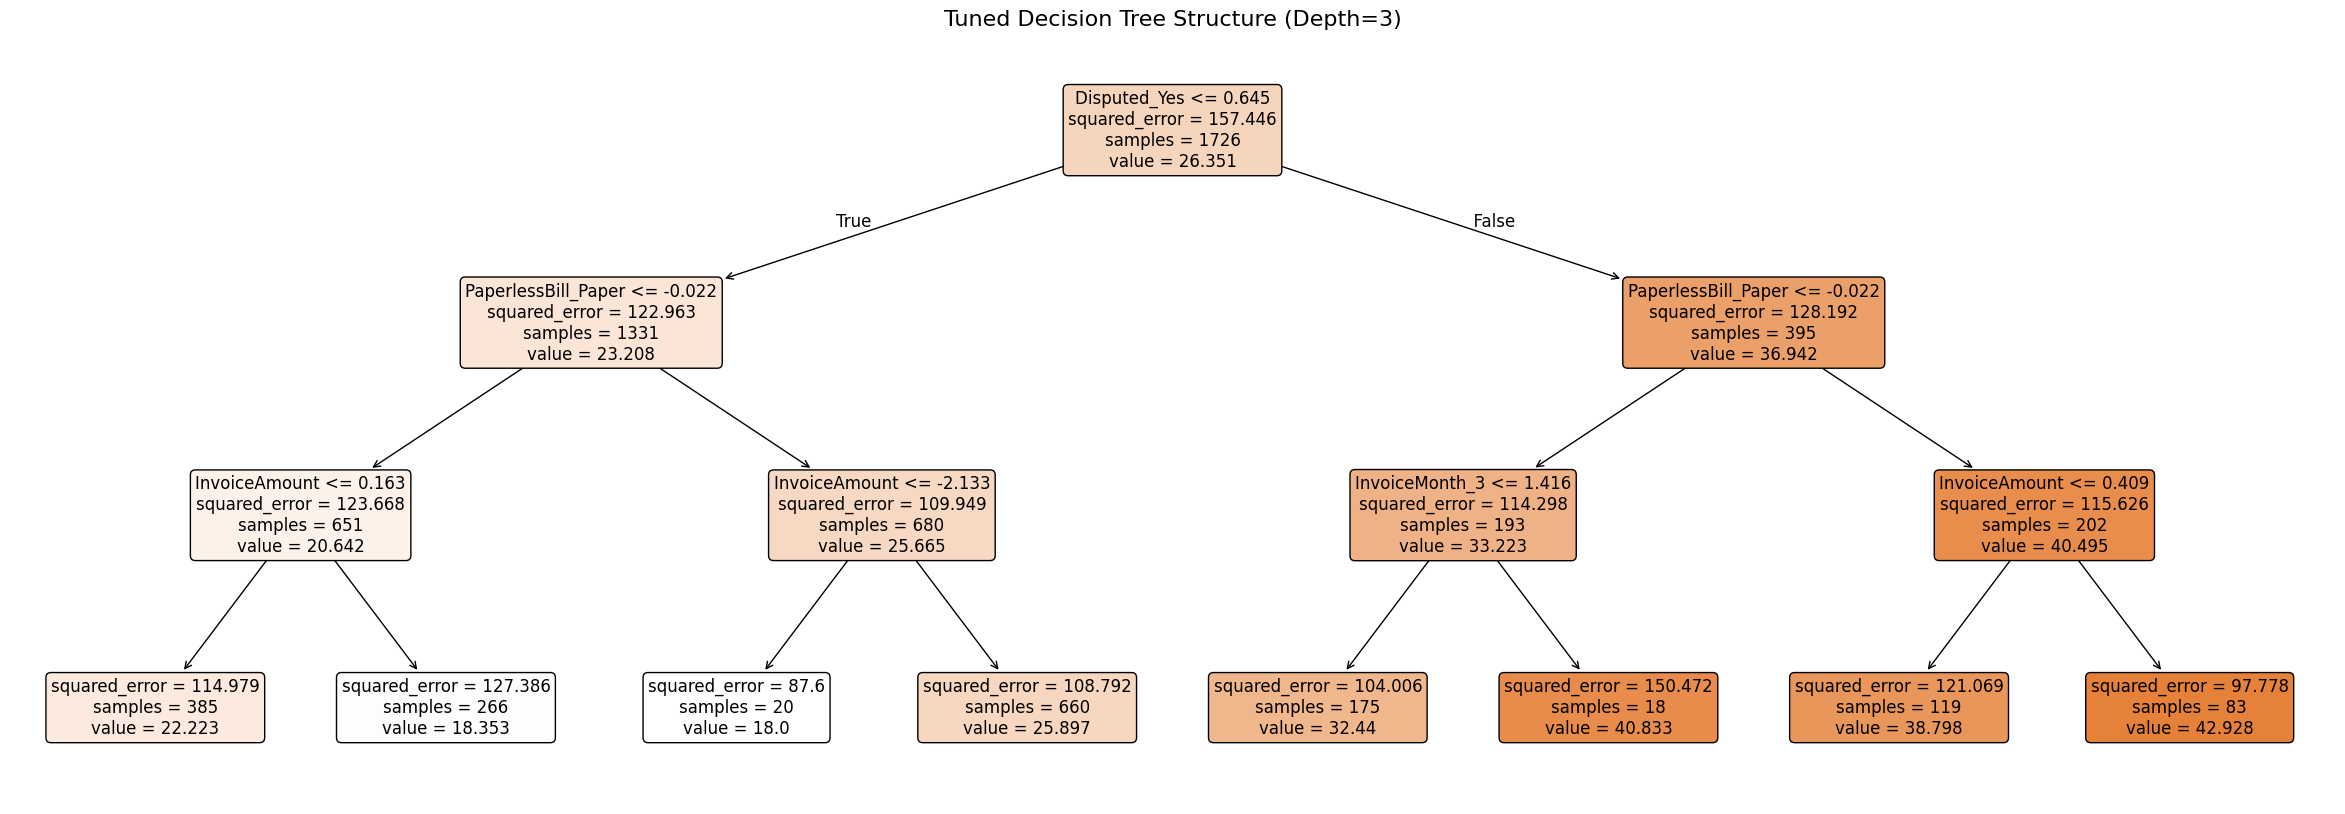

In [21]:
import matplotlib.pyplot as plt
from sklearn.tree import plot_tree

# 1. Set the size of the image
plt.figure(figsize=(30, 10))

# 2. Draw the tree structure
plot_tree(
    dt_tuned,
    feature_names=list(X_train.columns),  # Labels the splits with your actual column names
    filled=True,                           # Colors the boxes (darker colors mean different predictions)
    rounded=True,                          # Makes the boxes look clean with rounded corners
    fontsize=12                            # Makes the text inside the boxes readable
)

plt.title("Tuned Decision Tree Structure (Depth=3)", fontsize=16)
plt.show()

In [22]:
# Initialize a tree with our winning hyperparameters
# We train it on the raw (unscaled) X_train and y_train
dt_unscaled = DecisionTreeRegressor(
    max_depth=3,
    min_samples_split=2,
    min_samples_leaf=1,
    random_state=16
)
dt_unscaled.fit(X_train, y_train)

DecisionTreeRegressor(max_depth=3, random_state=16)

In [23]:
# 1. Make predictions on the unscaled data
y_train_pred_unscaled = dt_unscaled.predict(X_train)
y_test_pred_unscaled = dt_unscaled.predict(X_test)

# 2. Calculate evaluation metrics for the Testing Set
test_mae_unscaled = mean_absolute_error(y_test, y_test_pred_unscaled)
test_mse_unscaled = mean_squared_error(y_test, y_test_pred_unscaled)
test_rmse_unscaled = np.sqrt(test_mse_unscaled)
test_r2_unscaled = r2_score(y_test, y_test_pred_unscaled)

# 3. Print the results
print("=== Tuned Decision Tree (UNSCALED data) ===")
print(f"  Mean Absolute Error (MAE): {test_mae_unscaled:.2f} days")
print(f"  Mean Squared Error (MSE): {test_mse_unscaled:.2f}")
print(f"  Root Mean Squared Error (RMSE): {test_rmse_unscaled:.2f} days")
print(f"  R-squared (R2) Score: {test_r2_unscaled:.4f}")

=== Tuned Decision Tree (UNSCALED data) ===
  Mean Absolute Error (MAE): 8.50 days
  Mean Squared Error (MSE): 113.15
  Root Mean Squared Error (RMSE): 10.64 days
  R-squared (R2) Score: 0.1890


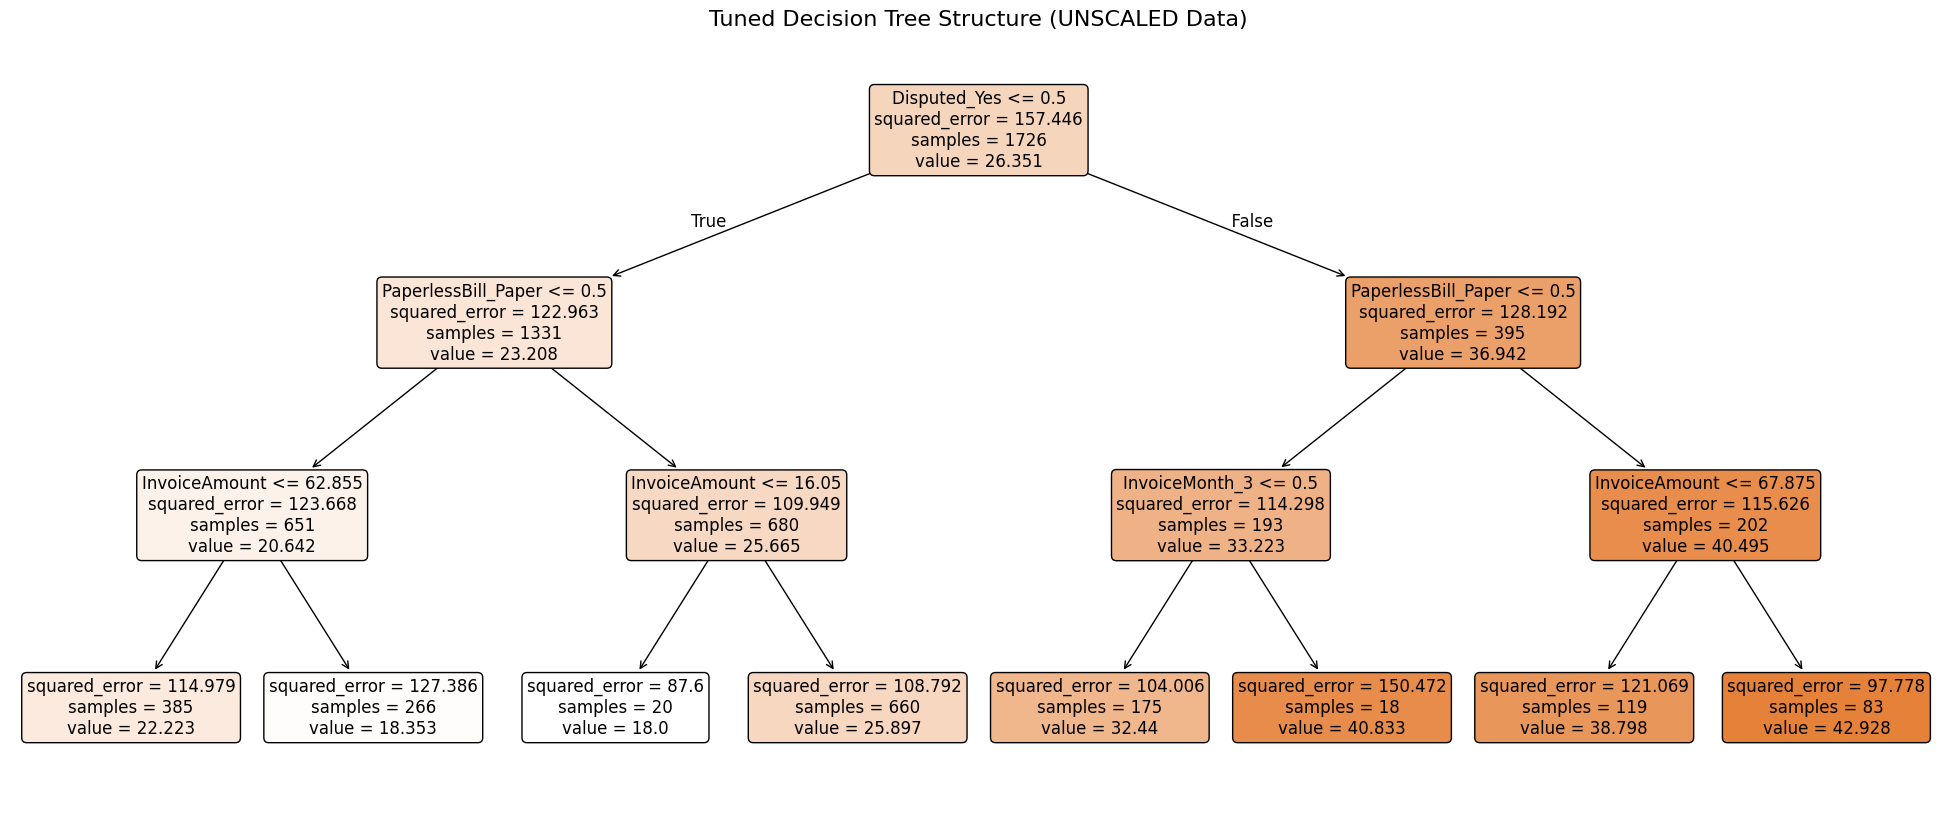

In [24]:
# 1. Set the size of the image
plt.figure(figsize=(25, 10))
# 2. Draw the tree structure for the UNSCALED model
plot_tree(
    dt_unscaled,
    feature_names=list(X_train.columns),  # Labels the splits with your actual column names
    filled=True,                           # Colors the boxes (darker means different predictions)
    rounded=True,                          # Rounded corners
    fontsize=12                            # Readable font size
)
plt.title("Tuned Decision Tree Structure (UNSCALED Data)", fontsize=16)
plt.show()

### 4.3. Random Forest Regressor

In this subsection, we develop a Random Forest Regressor, which is an ensemble model that trains multiple decision trees using bootstrap sampling and random feature selection. We will evaluate its performance and compare it against the baseline Linear Regression and the single Tuned Decision Tree.

#### 4.3.1. Default Random Forest

In this subsection, we train a default Random Forest Regressor where the individual trees grow without depth limits and evaluate all features at each split.

In [25]:
from sklearn.ensemble import RandomForestRegressor

# 1. Initialize the default Random Forest Regressor (unlimited depth)
rf_default = RandomForestRegressor(n_estimators=100, random_state=16)

# 2. Train the model on the unscaled training data
rf_default.fit(X_train, y_train)

# 3. Make predictions on both the training and testing sets
y_train_pred_rf = rf_default.predict(X_train)
y_test_pred_rf = rf_default.predict(X_test)

In [26]:
# 1. Calculate evaluation metrics for the Training Set
train_mae_rf = mean_absolute_error(y_train, y_train_pred_rf)
train_mse_rf = mean_squared_error(y_train, y_train_pred_rf)
train_rmse_rf = np.sqrt(train_mse_rf)
train_r2_rf = r2_score(y_train, y_train_pred_rf)

# 2. Print the training results clearly
print("=== Default Random Forest: Training Set Performance ===")
print(f"  Mean Absolute Error (MAE): {train_mae_rf:.2f} days")
print(f"  Mean Squared Error (MSE): {train_mse_rf:.2f}")
print(f"  Root Mean Squared Error (RMSE): {train_rmse_rf:.2f} days")
print(f"  R-squared (R2) Score: {train_r2_rf:.4f}")

=== Default Random Forest: Training Set Performance ===
  Mean Absolute Error (MAE): 3.44 days
  Mean Squared Error (MSE): 18.66
  Root Mean Squared Error (RMSE): 4.32 days
  R-squared (R2) Score: 0.8815


In [27]:
# 1. Calculate evaluation metrics for the Testing Set
test_mae_rf = mean_absolute_error(y_test, y_test_pred_rf)
test_mse_rf = mean_squared_error(y_test, y_test_pred_rf)
test_rmse_rf = np.sqrt(test_mse_rf)
test_r2_rf = r2_score(y_test, y_test_pred_rf)
# 2. Print the testing results clearly
print("=== Default Random Forest: Testing Set Performance ===")
print(f"  Mean Absolute Error (MAE): {test_mae_rf:.2f} days")
print(f"  Mean Squared Error (MSE): {test_mse_rf:.2f}")
print(f"  Root Mean Squared Error (RMSE): {test_rmse_rf:.2f} days")
print(f"  R-squared (R2) Score: {test_r2_rf:.4f}")

=== Default Random Forest: Testing Set Performance ===
  Mean Absolute Error (MAE): 9.20 days
  Mean Squared Error (MSE): 132.20
  Root Mean Squared Error (RMSE): 11.50 days
  R-squared (R2) Score: 0.0525


#### 4.3.2. Tuned Random Forest (Hyperparameter Tuning)

In this subsection, we use `GridSearchCV` with 5-fold cross-validation to search for the best combination of hyperparameters (`n_estimators`, `max_depth`, and `max_features`) to reduce correlation between the trees and prevent overfitting.

In [28]:
# Define the grid of hyperparameters to test for the Random Forest
rf_param_grid = {
    'n_estimators': [50, 100, 150],
    'max_depth': [3, 5, 7],
    'max_features': ['sqrt', 'log2', None]  # None means use all features (same as 1.0)
}

# Initialize the GridSearchCV object for Random Forest
# We lock the random_state=16 inside the RandomForestRegressor for reproducibility
rf_grid_search = GridSearchCV(
    estimator=RandomForestRegressor(random_state=16),
    param_grid=rf_param_grid,

    # 5-fold cross-validation
    cv=5,

    # Select the winning parameters based on the highest R-squared score
    scoring='r2'
)

# Run the Grid Search to train all the combinations and find the best Random Forest
rf_grid_search.fit(X_train, y_train)

GridSearchCV(cv=5, estimator=RandomForestRegressor(random_state=16),
             param_grid={'max_depth': [3, 5, 7],
                         'max_features': ['sqrt', 'log2', None],
                         'n_estimators': [50, 100, 150]},
             scoring='r2')

In [29]:
# 1. Extract the best Random Forest model
rf_tuned = rf_grid_search.best_estimator_

# 2. Make predictions using the tuned model
y_train_pred_rf_tuned = rf_tuned.predict(X_train)
y_test_pred_rf_tuned = rf_tuned.predict(X_test)

In [30]:
# 1. Calculate evaluation metrics for the Tuned Random Forest (Training Set)
train_mae_rf_tuned = mean_absolute_error(y_train, y_train_pred_rf_tuned)
train_mse_rf_tuned = mean_squared_error(y_train, y_train_pred_rf_tuned)
train_rmse_rf_tuned = np.sqrt(train_mse_rf_tuned)
train_r2_rf_tuned = r2_score(y_train, y_train_pred_rf_tuned)

# 2. Calculate evaluation metrics for the Tuned Random Forest (Testing Set)
test_mae_rf_tuned = mean_absolute_error(y_test, y_test_pred_rf_tuned)
test_mse_rf_tuned = mean_squared_error(y_test, y_test_pred_rf_tuned)
test_rmse_rf_tuned = np.sqrt(test_mse_rf_tuned)
test_r2_rf_tuned = r2_score(y_test, y_test_pred_rf_tuned)

# 3. Print the results
print("=== Tuned Random Forest Evaluation ===")
print("\nTraining Set Performance:")
print(f"  Mean Absolute Error (MAE): {train_mae_rf_tuned:.2f} days")
print(f"  Mean Squared Error (MSE): {train_mse_rf_tuned:.2f}")
print(f"  Root Mean Squared Error (RMSE): {train_rmse_rf_tuned:.2f} days")
print(f"  R-squared (R2) Score: {train_r2_rf_tuned:.4f}")

print("\nTesting Set Performance:")
print(f"  Mean Absolute Error (MAE): {test_mae_rf_tuned:.2f} days")
print(f"  Mean Squared Error (MSE): {test_mse_rf_tuned:.2f}")
print(f"  Root Mean Squared Error (RMSE): {test_rmse_rf_tuned:.2f} days")
print(f"  R-squared (R2) Score: {test_r2_rf_tuned:.4f}")

=== Tuned Random Forest Evaluation ===

Training Set Performance:
  Mean Absolute Error (MAE): 8.53 days
  Mean Squared Error (MSE): 112.08
  Root Mean Squared Error (RMSE): 10.59 days
  R-squared (R2) Score: 0.2881

Testing Set Performance:
  Mean Absolute Error (MAE): 8.43 days
  Mean Squared Error (MSE): 111.72
  Root Mean Squared Error (RMSE): 10.57 days
  R-squared (R2) Score: 0.1993


In [31]:
# Create a dictionary containing the test results of all 3 models
summary_data = {
    "Model": ["Linear Regression (Baseline)", "Tuned Decision Tree", "Tuned Random Forest"],
    "MAE (days)": [test_mae, test_mae_tuned, test_mae_rf_tuned],
    "MSE": [test_mse, test_mse_tuned, test_mse_rf_tuned],
    "RMSE (days)": [test_rmse, test_rmse_tuned, test_rmse_rf_tuned],
    "R2 Score": [test_r2, test_r2_tuned, test_r2_rf_tuned]
}

# Convert to DataFrame
comparison_df = pd.DataFrame(summary_data)

# Format the decimal places for a clean look
comparison_df["MAE (days)"] = comparison_df["MAE (days)"].map("{:.2f}".format)
comparison_df["MSE"] = comparison_df["MSE"].map("{:.2f}".format)
comparison_df["RMSE (days)"] = comparison_df["RMSE (days)"].map("{:.2f}".format)
comparison_df["R2 Score"] = comparison_df["R2 Score"].map("{:.4f}".format)

# Display the comparison table
comparison_df

,Model,MAE (days),MSE,RMSE (days),R2 Score
0,Linear Regression (Baseline),8.52,112.94,10.63,0.1905
1,Tuned Decision Tree,8.50,113.15,10.64,0.1890
2,Tuned Random Forest,8.43,111.72,10.57,0.1993


## 5. Model Development (Classification)

In this section, we will train models to predict if a borrower will default on their loan (the `loan_status` column: 1 for default, 0 for safe). We will compare three models:
1. **Logistic Regression** (our simple baseline model)
2. **K-Nearest Neighbors (KNN)** (which uses distance to find similar borrowers)
3. **Random Forest Classifier** (which uses a group of decision trees)

We will check how good our models are using standard scores: Accuracy, Precision, Recall, F1-Score, and ROC-AUC.

### 5.1. Dataset Selection & Exploratory Data Analysis (EDA)

In this part, we load the Credit Risk dataset from the web. We take a stable random sample of 5,000 rows for faster training, and inspect the columns. We will check the data types and look for missing values that we need to clean.

In [32]:
# 1. Load the Credit Risk dataset from the GitHub link
url = "https://raw.githubusercontent.com/PhilChodrow/ml-notes/main/data/credit-risk/credit_risk_dataset.csv"
df_raw = pd.read_csv(url)

# 2. Take a random sample of 5,000 rows
# We use random_state=42 so we always get the exact same 5,000 rows when we rerun the notebook
df_class = df_raw.sample(n=5000, random_state=42).reset_index(drop=True)

# 3. Print the size of the sampled dataset
print("Sampled dataset size (rows, columns):", df_class.shape)

# 4. Print columns, types, and missing values
print("\nDataset Info:")
df_class.info()

# 5. Print the first rows of the dataset
print("\n")
print(df_class.head())

Sampled dataset size (rows, columns): (5000, 12)

Dataset Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 12 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   person_age                  5000 non-null   int64  
 1   person_income               5000 non-null   int64  
 2   person_home_ownership       5000 non-null   object 
 3   person_emp_length           4864 non-null   float64
 4   loan_intent                 5000 non-null   object 
 5   loan_grade                  5000 non-null   object 
 6   loan_amnt                   5000 non-null   int64  
 7   loan_int_rate               4516 non-null   float64
 8   loan_status                 5000 non-null   int64  
 9   loan_percent_income         5000 non-null   float64
 10  cb_person_default_on_file   5000 non-null   object 
 11  cb_person_cred_hist_length  5000 non-null   int64  
dtypes: float64(3), int64(5), o

In [33]:
# 1. Count how many loans are safe (0) vs defaulted (1)
print("Loan status counts (0 = safe, 1 = defaulted):")
print(df_class['loan_status'].value_counts())

# 2. Show the percentage of each outcome
print("\nPercentage of each outcome (%):")
print(df_class['loan_status'].value_counts(normalize=True) * 100)

Loan status counts (0 = safe, 1 = defaulted):
loan_status
0    3874
1    1126
Name: count, dtype: int64

Percentage of each outcome (%):
loan_status
0    77.48
1    22.52
Name: proportion, dtype: float64


#### 5.1.1. Visualizing Credit Risk Factors

In this section, we create two plots to see how interest rates and loan grades relate to loan defaults. This helps us find the strongest patterns in our data.

/tmp/ipykernel_4517/2494221921.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.countplot(x='loan_status', data=df_class, palette='viridis')


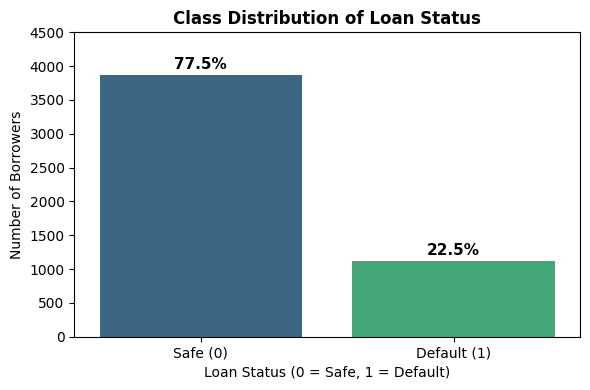

In [34]:
# 1. Set the figure size
plt.figure(figsize=(6, 4))
# 2. Create the countplot using the 'loan_status' column from df_class
ax = sns.countplot(x='loan_status', data=df_class, palette='viridis')
# 3. Calculate the total number of samples in df_class
total_samples = len(df_class)
# 4. Loop through the bars to calculate and display the percentage on top of each
for bar in ax.patches:
    height = bar.get_height()
    percentage = f'{100 * height / total_samples:.1f}%'
    # Position the text on top of each bar
    ax.annotate(percentage,
                (bar.get_x() + bar.get_width() / 2, height + 40),
                ha='center',
                va='bottom',
                fontsize=11,
                fontweight='bold')
# 5. Set labels, title, and limits
plt.title("Class Distribution of Loan Status", fontsize=12, fontweight='bold')
plt.xlabel("Loan Status (0 = Safe, 1 = Default)", fontsize=10)
plt.ylabel("Number of Borrowers", fontsize=10)
plt.xticks(ticks=[0, 1], labels=['Safe (0)', 'Default (1)'])
plt.ylim(0, total_samples * 0.9) # Give some extra vertical space for the text
# 6. Render the plot
plt.tight_layout()
plt.show()

/tmp/ipykernel_4517/367864778.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='loan_status', y='loan_int_rate', data=df_class, ax=axes[0], palette='pastel')


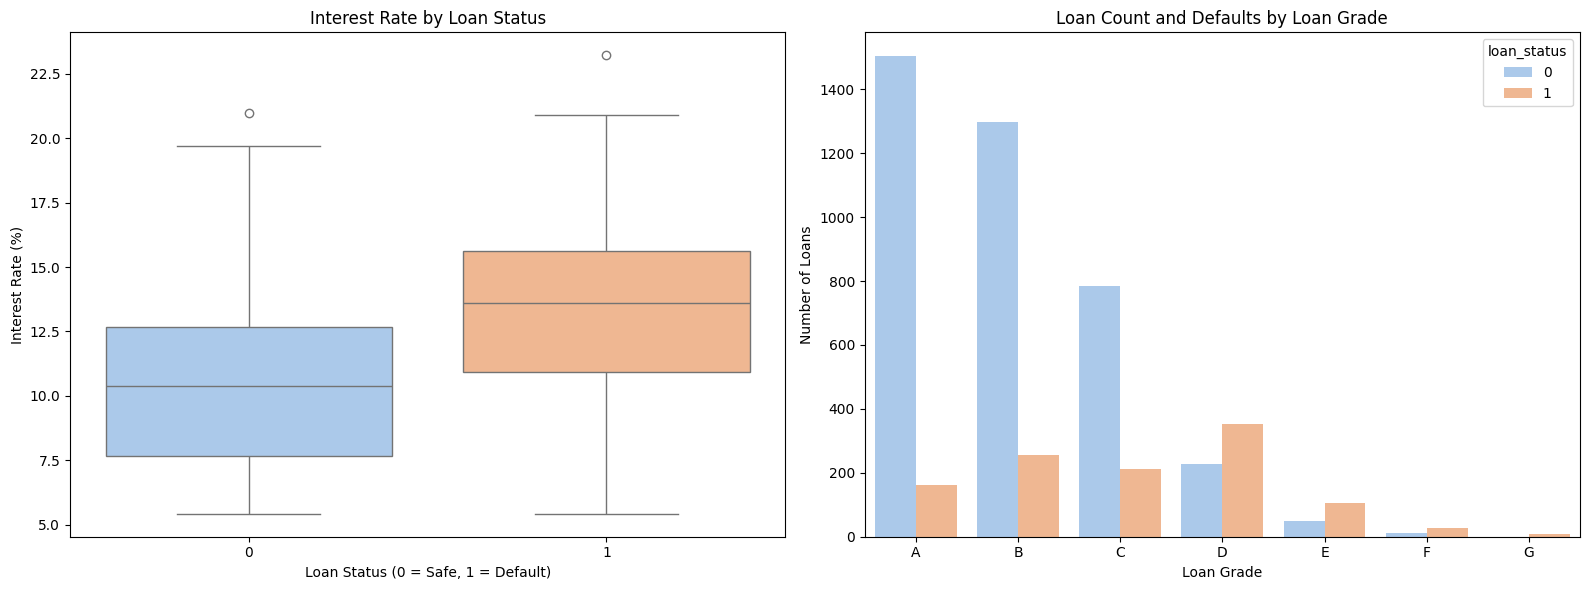

In [35]:
# Create a figure with 2 subplots side-by-side
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# 1. Boxplot: Loan Interest Rate by Loan Status
sns.boxplot(x='loan_status', y='loan_int_rate', data=df_class, ax=axes[0], palette='pastel')
axes[0].set_title('Interest Rate by Loan Status')
axes[0].set_xlabel('Loan Status (0 = Safe, 1 = Default)')
axes[0].set_ylabel('Interest Rate (%)')

# 2. Countplot: Loan Grade count grouped by Loan Status
# We sort the grades from A to G for a clean look
grade_order = sorted(df_class['loan_grade'].unique())
sns.countplot(x='loan_grade', hue='loan_status', data=df_class, ax=axes[1], order=grade_order, palette='pastel')
axes[1].set_title('Loan Count and Defaults by Loan Grade')
axes[1].set_xlabel('Loan Grade')
axes[1].set_ylabel('Number of Loans')

plt.tight_layout()
plt.show()

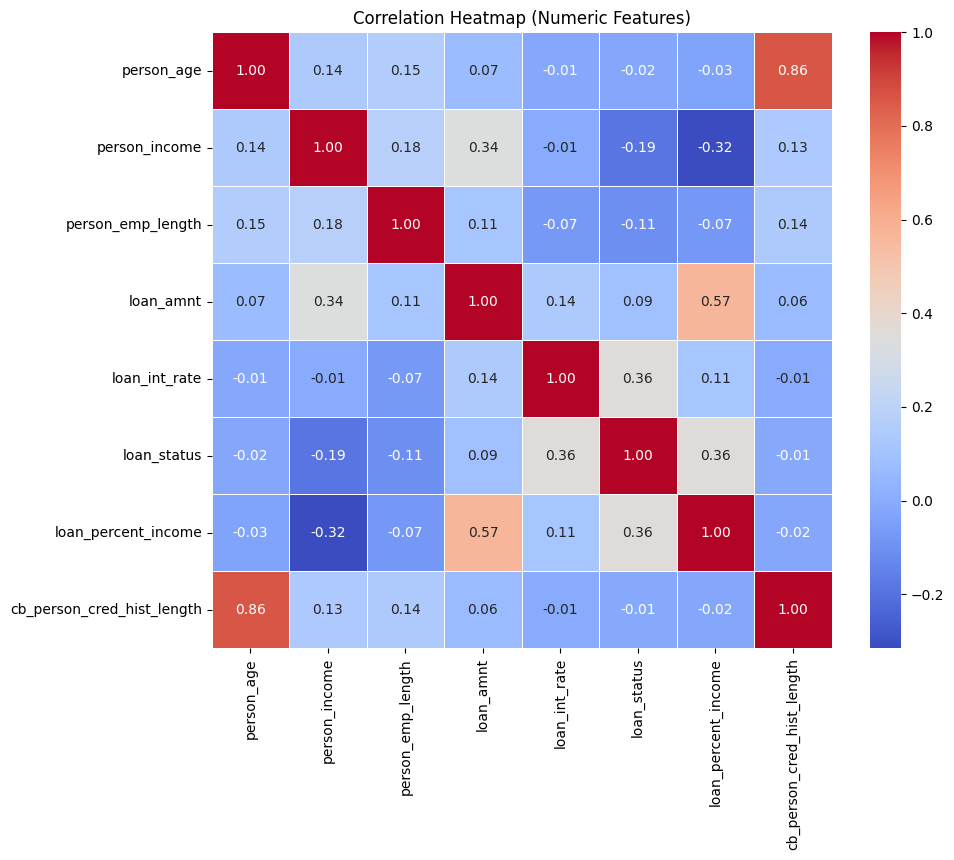

In [36]:
# 1. Select only the numeric columns from the dataset
numeric_cols = df_class.select_dtypes(include=['int64', 'float64'])

# 2. Calculate the correlation matrix
corr_matrix = numeric_cols.corr()

# 3. Plot the correlation heatmap
plt.figure(figsize=(10, 8))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt=".2f", linewidths=0.5)
plt.title("Correlation Heatmap (Numeric Features)")
plt.show()

### 5.2. Data Preprocessing

In this subsection, we clean the dataset to prepare it for model training. We will fill in the missing values in our columns using the median value, and then perform train-test splitting, one-hot encoding, and feature scaling.

#### 5.2.1. Handling Missing Values

In this step, we find and fix the missing values in our dataset. The columns `person_emp_length` (employment length) and `loan_int_rate` (interest rate) have empty spaces. We fill these empty spaces with the median value of each column. We use the median because it is not affected by extreme outlier values.

In [37]:
# 1. Calculate the median for both columns
emp_length_median = df_class['person_emp_length'].median()
int_rate_median = df_class['loan_int_rate'].median()

# 2. Fill the missing values with their respective medians
df_class['person_emp_length'] = df_class['person_emp_length'].fillna(emp_length_median)
df_class['loan_int_rate'] = df_class['loan_int_rate'].fillna(int_rate_median)

# 3. Check again to confirm there are no more missing values
print("Remaining missing values in each column:")
print(df_class.isnull().sum())

Remaining missing values in each column:
person_age                    0
person_income                 0
person_home_ownership         0
person_emp_length             0
loan_intent                   0
loan_grade                    0
loan_amnt                     0
loan_int_rate                 0
loan_status                   0
loan_percent_income           0
cb_person_default_on_file     0
cb_person_cred_hist_length    0
dtype: int64


#### 5.2.2. Train-Test Split

In this step, we split our data. We separate the predictive features (`X`) from the target variable (`y`, which is `loan_status`). Then, we divide the data into a training set ($70\%$) and a testing set ($30\%$). We lock the split with `random_state=16` so that we get the exact same groups of rows every time we run the code.

In [38]:
# 1. Separate features (X) and target (y)
X = df_class.drop(columns=['loan_status'])
y = df_class['loan_status']

# 2. Perform train-test split (70% training, 30% testing)
# We use random_state=16 so we always get the exact same split when we rerun the notebook
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.30, random_state=16)

# 3. Print the shapes to confirm
print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)

X_train shape: (3500, 11)
X_test shape: (1500, 11)


#### 5.2.3. One-Hot Encoding

In this step, we convert our text columns (categorical features like home ownership, loan intent, and loan grade) into binary numbers ($0$s and $1$s). We use `drop_first=True` to remove redundant columns and prevent multicollinearity. Finally, we align the train and test columns so they match exactly in the same order.

In [39]:
# 1. Convert categorical columns to binary numbers (0 and 1)
X_train_encoded = pd.get_dummies(X_train, columns=['person_home_ownership', 'loan_intent', 'loan_grade', 'cb_person_default_on_file'], drop_first=True)
X_test_encoded = pd.get_dummies(X_test, columns=['person_home_ownership', 'loan_intent', 'loan_grade', 'cb_person_default_on_file'], drop_first=True)

# 2. Make sure the test set has the exact same columns as the train set.
# If a column is missing in the test set, create it and fill it with 0; we do this especially for the grade loans since grade G might be missing from either the training or the testing dataset
X_train_encoded, X_test_encoded = X_train_encoded.align(X_test_encoded, join='left', axis=1, fill_value=0)

# 3. Print the new column counts
print("Features after encoding (train):", X_train_encoded.shape[1])
print("Features after encoding (test):", X_test_encoded.shape[1])

Features after encoding (train): 22
Features after encoding (test): 22


#### 5.2.4. Feature Scaling

In this step, we standardize our numerical features using `StandardScaler`. This changes the variables so that they all have a mean of $0$ and a variance of $1$. This is very important for models like K-Nearest Neighbors (KNN) and Logistic Regression, ensuring all features are treated equally.

In [40]:
# 1. Initialize the StandardScaler
scaler_class = StandardScaler()

# 2. Fit on the training data and scale it
X_train_scaled = scaler_class.fit_transform(X_train_encoded)

# 3. Scale the testing data using the same scaler settings
X_test_scaled = scaler_class.transform(X_test_encoded)

## 6. Model Training & Evaluation (Classification)

In this section, we train our three classification models (Logistic Regression, KNN, and Random Forest) on our scaled training data. We will evaluate their performance on the test data.

### 6.1. Logistic Regression (Baseline Classifier)

In this part, we train a Logistic Regression model as our baseline. We will use the default solver (`lbfgs`) and lock our random state to ensure reproducible results.

In [41]:
from sklearn.linear_model import LogisticRegression

lr_model = LogisticRegression(random_state=16)

# train the model
lr_model.fit(X_train_scaled, y_train)

# get the predictions
y_train_pred_lr = lr_model.predict(X_train_scaled)
y_test_pred_lr = lr_model.predict(X_test_scaled)

In [42]:
# 1. Import the classification metrics
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score

# 2. Get the predicted probabilities (needed for ROC-AUC)
y_train_prob_lr = lr_model.predict_proba(X_train_scaled)[:, 1]
y_test_prob_lr = lr_model.predict_proba(X_test_scaled)[:, 1]

# 3. Calculate metrics for the Training Set
train_acc = accuracy_score(y_train, y_train_pred_lr)
train_prec = precision_score(y_train, y_train_pred_lr)
train_rec = recall_score(y_train, y_train_pred_lr)
train_f1 = f1_score(y_train, y_train_pred_lr)
train_auc = roc_auc_score(y_train, y_train_prob_lr)

# 4. Calculate metrics for the Testing Set
test_acc = accuracy_score(y_test, y_test_pred_lr)
test_prec = precision_score(y_test, y_test_pred_lr)
test_rec = recall_score(y_test, y_test_pred_lr)
test_f1 = f1_score(y_test, y_test_pred_lr)
test_auc = roc_auc_score(y_test, y_test_prob_lr)

# 5. Print the results clearly
print("=== Logistic Regression Performance ===")
print("\nTraining Set Performance:")
print(f"  Accuracy:  {train_acc:.4f}")
print(f"  Precision: {train_prec:.4f}")
print(f"  Recall:    {train_rec:.4f}")
print(f"  F1-Score:  {train_f1:.4f}")
print(f"  ROC-AUC:   {train_auc:.4f}")

print("\nTesting Set Performance:")
print(f"  Accuracy:  {test_acc:.4f}")
print(f"  Precision: {test_prec:.4f}")
print(f"  Recall:    {test_rec:.4f}")
print(f"  F1-Score:  {test_f1:.4f}")
print(f"  ROC-AUC:   {test_auc:.4f}")

=== Logistic Regression Performance ===

Training Set Performance:
  Accuracy:  0.8683
  Precision: 0.7657
  Recall:    0.5725
  F1-Score:  0.6552
  ROC-AUC:   0.8833

Testing Set Performance:
  Accuracy:  0.8533
  Precision: 0.7878
  Recall:    0.5346
  F1-Score:  0.6370
  ROC-AUC:   0.8530


### 6.2 K-Nearest Neighbors (KNN)

In this subsection, we train a K-Nearest Neighbors (KNN) classifier. This model classifies a borrower based on the majority vote of their $K$ most similar neighbors in the feature space. We will evaluate its performance on both the training and testing datasets.

In [43]:
from sklearn.neighbors import KNeighborsClassifier

# 1. Initialize the KNN classifier
# We set n_neighbors=5 (meaning we look at the 5 closest neighbors)
knn_model = KNeighborsClassifier(n_neighbors=5)

# 2. Train the model using the scaled training data
knn_model.fit(X_train_scaled, y_train)

# 3. Make predictions on both the training and testing sets
y_train_pred_knn = knn_model.predict(X_train_scaled)
y_test_pred_knn = knn_model.predict(X_test_scaled)

In [44]:
# 1. Get the predicted probabilities for KNN (needed for ROC-AUC)
y_train_prob_knn = knn_model.predict_proba(X_train_scaled)[:, 1]
y_test_prob_knn = knn_model.predict_proba(X_test_scaled)[:, 1]

# 2. Calculate metrics for the Training Set
train_acc_knn = accuracy_score(y_train, y_train_pred_knn)
train_prec_knn = precision_score(y_train, y_train_pred_knn)
train_rec_knn = recall_score(y_train, y_train_pred_knn)
train_f1_knn = f1_score(y_train, y_train_pred_knn)
train_auc_knn = roc_auc_score(y_train, y_train_prob_knn)

# 3. Calculate metrics for the Testing Set
test_acc_knn = accuracy_score(y_test, y_test_pred_knn)
test_prec_knn = precision_score(y_test, y_test_pred_knn)
test_rec_knn = recall_score(y_test, y_test_pred_knn)
test_f1_knn = f1_score(y_test, y_test_pred_knn)
test_auc_knn = roc_auc_score(y_test, y_test_prob_knn)

# 4. Print the results clearly
print("=== KNN Performance (K=5) ===")
print("\nTraining Set Performance:")
print(f"  Accuracy:  {train_acc_knn:.4f}")
print(f"  Precision: {train_prec_knn:.4f}")
print(f"  Recall:    {train_rec_knn:.4f}")
print(f"  F1-Score:  {train_f1_knn:.4f}")
print(f"  ROC-AUC:   {train_auc_knn:.4f}")

print("\nTesting Set Performance:")
print(f"  Accuracy:  {test_acc_knn:.4f}")
print(f"  Precision: {test_prec_knn:.4f}")
print(f"  Recall:    {test_rec_knn:.4f}")
print(f"  F1-Score:  {test_f1_knn:.4f}")
print(f"  ROC-AUC:   {test_auc_knn:.4f}")

=== KNN Performance (K=5) ===

Training Set Performance:
  Accuracy:  0.9094
  Precision: 0.8810
  Recall:    0.6771
  F1-Score:  0.7657
  ROC-AUC:   0.9556

Testing Set Performance:
  Accuracy:  0.8693
  Precision: 0.8161
  Recall:    0.5900
  F1-Score:  0.6849
  ROC-AUC:   0.8252


### 6.3 Random Forest Classifier

In this subsection, we develop a Random Forest Classifier. We will first train a default forest using scikit-learn's default parameters and then use hyperparameter tuning to find the best configuration.

#### 6.3.1 Default Random Forest Classifier

In this part, we train a default Random Forest Classifier with 100 trees and no depth limits to see its baseline performance on our credit risk dataset.

In [45]:
from sklearn.ensemble import RandomForestClassifier

# 1. Initialize the default Random Forest Classifier
# We build 100 trees and lock the random state for reproducibility
rf_default = RandomForestClassifier(n_estimators=100, random_state=16)

# 2. Train the model using the scaled training data
rf_default.fit(X_train_scaled, y_train)

# 3. Make predictions on both the training and testing sets
y_train_pred_rf = rf_default.predict(X_train_scaled)
y_test_pred_rf = rf_default.predict(X_test_scaled)

In [46]:
# 1. Get the predicted probabilities for Random Forest (needed for ROC-AUC)
y_train_prob_rf = rf_default.predict_proba(X_train_scaled)[:, 1]
y_test_prob_rf = rf_default.predict_proba(X_test_scaled)[:, 1]

# 2. Calculate metrics for the Training Set
train_acc_rf = accuracy_score(y_train, y_train_pred_rf)
train_prec_rf = precision_score(y_train, y_train_pred_rf)
train_rec_rf = recall_score(y_train, y_train_pred_rf)
train_f1_rf = f1_score(y_train, y_train_pred_rf)
train_auc_rf = roc_auc_score(y_train, y_train_prob_rf)

# 3. Calculate metrics for the Testing Set
test_acc_rf = accuracy_score(y_test, y_test_pred_rf)
test_prec_rf = precision_score(y_test, y_test_pred_rf)
test_rec_rf = recall_score(y_test, y_test_pred_rf)
test_f1_rf = f1_score(y_test, y_test_pred_rf)
test_auc_rf = roc_auc_score(y_test, y_test_prob_rf)

# 4. Print the results clearly
print("=== Default Random Forest Performance ===")
print("\nTraining Set Performance:")
print(f"  Accuracy:  {train_acc_rf:.4f}")
print(f"  Precision: {train_prec_rf:.4f}")
print(f"  Recall:    {train_rec_rf:.4f}")
print(f"  F1-Score:  {train_f1_rf:.4f}")
print(f"  ROC-AUC:   {train_auc_rf:.4f}")

print("\nTesting Set Performance:")
print(f"  Accuracy:  {test_acc_rf:.4f}")
print(f"  Precision: {test_prec_rf:.4f}")
print(f"  Recall:    {test_rec_rf:.4f}")
print(f"  F1-Score:  {test_f1_rf:.4f}")
print(f"  ROC-AUC:   {test_auc_rf:.4f}")

=== Default Random Forest Performance ===

Training Set Performance:
  Accuracy:  0.9997
  Precision: 1.0000
  Recall:    0.9987
  F1-Score:  0.9993
  ROC-AUC:   1.0000

Testing Set Performance:
  Accuracy:  0.9033
  Precision: 0.9000
  Recall:    0.6731
  F1-Score:  0.7702
  ROC-AUC:   0.8994


#### 6.3.2. Tuned Random Forest Classifier

In this part, we use `GridSearchCV` with 5-fold cross-validation to search for the best combination of hyperparameters (`n_estimators`, `max_depth`, and `max_features`) to reduce overfitting and improve our testing metrics.

In [47]:
# 1. Define the grid of hyperparameters to test
rf_class_param_grid = {
    'n_estimators': [50, 100, 150],
    'max_depth': [3, 5, 7],
    'max_features': ['sqrt', 'log2', None]  # None means use all features
}

# 2. Initialize the GridSearchCV engine
# We evaluate combinations based on their ROC-AUC score
rf_class_grid_search = GridSearchCV(
    estimator=RandomForestClassifier(random_state=16),
    param_grid=rf_class_param_grid,
    cv=5,
    scoring='roc_auc'
)

# 3. Run the search on the scaled training data
# (This will take about 15-20 seconds to run in Google Colab)
rf_class_grid_search.fit(X_train_scaled, y_train)

GridSearchCV(cv=5, estimator=RandomForestClassifier(random_state=16),
             param_grid={'max_depth': [3, 5, 7],
                         'max_features': ['sqrt', 'log2', None],
                         'n_estimators': [50, 100, 150]},
             scoring='roc_auc')

In [48]:
# 1. Extract the best model from the grid search
rf_tuned = rf_class_grid_search.best_estimator_

# 2. Make predictions on both the training and testing sets
y_train_pred_rf_tuned = rf_tuned.predict(X_train_scaled)
y_test_pred_rf_tuned = rf_tuned.predict(X_test_scaled)

# 3. Get the predicted probabilities (needed for ROC-AUC)
y_train_prob_rf_tuned = rf_tuned.predict_proba(X_train_scaled)[:, 1]
y_test_prob_rf_tuned = rf_tuned.predict_proba(X_test_scaled)[:, 1]

# 4. Calculate metrics for the Training Set
train_acc_rf_tuned = accuracy_score(y_train, y_train_pred_rf_tuned)
train_prec_rf_tuned = precision_score(y_train, y_train_pred_rf_tuned)
train_rec_rf_tuned = recall_score(y_train, y_train_pred_rf_tuned)
train_f1_rf_tuned = f1_score(y_train, y_train_pred_rf_tuned)
train_auc_rf_tuned = roc_auc_score(y_train, y_train_prob_rf_tuned)

# 5. Calculate metrics for the Testing Set
test_acc_rf_tuned = accuracy_score(y_test, y_test_pred_rf_tuned)
test_prec_rf_tuned = precision_score(y_test, y_test_pred_rf_tuned)
test_rec_rf_tuned = recall_score(y_test, y_test_pred_rf_tuned)
test_f1_rf_tuned = f1_score(y_test, y_test_pred_rf_tuned)
test_auc_rf_tuned = roc_auc_score(y_test, y_test_prob_rf_tuned)

# 6. Print the results clearly
print("=== Tuned Random Forest Performance ===")
print("\nTraining Set Performance:")
print(f"  Accuracy:  {train_acc_rf_tuned:.4f}")
print(f"  Precision: {train_prec_rf_tuned:.4f}")
print(f"  Recall:    {train_rec_rf_tuned:.4f}")
print(f"  F1-Score:  {train_f1_rf_tuned:.4f}")
print(f"  ROC-AUC:   {train_auc_rf_tuned:.4f}")

print("\nTesting Set Performance:")
print(f"  Accuracy:  {test_acc_rf_tuned:.4f}")
print(f"  Precision: {test_prec_rf_tuned:.4f}")
print(f"  Recall:    {test_rec_rf_tuned:.4f}")
print(f"  F1-Score:  {test_f1_rf_tuned:.4f}")
print(f"  ROC-AUC:   {test_auc_rf_tuned:.4f}")

=== Tuned Random Forest Performance ===

Training Set Performance:
  Accuracy:  0.9377
  Precision: 0.9659
  Recall:    0.7412
  F1-Score:  0.8388
  ROC-AUC:   0.9440

Testing Set Performance:
  Accuracy:  0.8960
  Precision: 0.9116
  Recall:    0.6288
  F1-Score:  0.7443
  ROC-AUC:   0.8910


#### 6.3.3. Random Forest Results Discussion

The Tuned Random Forest Classifier (`max_depth=7`, `n_estimators=150`) successfully controlled the severe overfitting seen in the default model:
* The F1-Score gap between training and testing was reduced from 22.9% to 9.5%.
* The ROC-AUC gap was reduced from 10.1% to 5.3%.

Although the default model achieved slightly higher test scores due to local memorization, the tuned model is much more robust and represents a major improvement over both the baseline Logistic Regression (F1: 0.7443 vs 0.6370) and KNN (F1: 0.7443 vs 0.6849).

In [49]:
import pandas as pd

# 1. Create a dictionary with the test results of all three models
classification_results = {
    'Model': ['Logistic Regression', 'K-Nearest Neighbors (K=5)', 'Tuned Random Forest'],
    'Accuracy': [test_acc, test_acc_knn, test_acc_rf_tuned],
    'Precision': [test_prec, test_prec_knn, test_prec_rf_tuned],
    'Recall': [test_rec, test_rec_knn, test_rec_rf_tuned],
    'F1-Score': [test_f1, test_f1_knn, test_f1_rf_tuned],
    'ROC-AUC': [test_auc, test_auc_knn, test_auc_rf_tuned]
}

# 2. Convert dictionary to a DataFrame
df_class_comparison = pd.DataFrame(classification_results)

# 3. Format numbers to 4 decimal places
df_class_comparison = df_class_comparison.round(4)

# 4. Display the DataFrame
print("=== Classification Model Comparison (Testing Set) ===")
df_class_comparison

=== Classification Model Comparison (Testing Set) ===


,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,Logistic Regression,0.8533,0.7878,0.5346,0.6370,0.8530
1,K-Nearest Neighbors (K=5),0.8693,0.8161,0.5900,0.6849,0.8252
2,Tuned Random Forest,0.8960,0.9116,0.6288,0.7443,0.8910


## 7. Artificial Intelligence (AI) Disclosure

In accordance with academic integrity guidelines, it is disclosed that an AI assistant (Antigravity by Google DeepMind) was utilized during the development of this project.

The AI was used as a pair-programming assistant to:
* Suggest code structures for preprocessing and model evaluation.
* Explain the underlying mathematical concepts (such as the sigmoid function, Gini Impurity, and Newton-Raphson optimization step).
* Assist in writing clean documentation comments.

All code executions, diagnostic checks, and final interpretations of the results were performed and verified independently by the student.